# Plant Leaf Disease Detection - full workflow
**INT422 Deep Learning** - Arpita Mishra (12303670, K2M2359, Roll No. 03)

This notebook walks through the whole project. With `RETRAIN = False` it loads the trained models and
recomputes every evaluation live. Set `RETRAIN = True` to run all training scripts first
(under an hour on a dual-core CPU).

In [1]:
RETRAIN = False

import os, sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ["MPLBACKEND"] = "module://matplotlib_inline.backend_inline"

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
from src import config as C
from src.common import *
from src.common import load_split, predict, read_metrics, to_float, train_dataset, eval_dataset
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| devices:", tf.config.list_physical_devices())
if RETRAIN:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.run_all"], check=True)
metrics = read_metrics()

TensorFlow 2.21.0 | Keras 3.15.1 | devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Data (Units I and III)
`python -m src.prepare_data` downloads the subset. Images of one leaf never cross splits.

In [2]:
df = load_manifest()
display(pd.crosstab(df.class_dir, df.split, margins=True))
print("max splits per leaf:", df.groupby(["class_dir", "leaf_id"]).split.nunique().max())
xtr, ytr, _ = load_split("train"); xva, yva, _ = load_split("val"); xte, yte, _ = load_split("test")

split,test,train,val,All
class_dir,,,,
"Pepper,_bell___Bacterial_spot",44,211,45,300
"Pepper,_bell___healthy",45,210,45,300
Potato___Early_blight,44,212,44,300
Potato___Late_blight,44,212,44,300
Potato___healthy,20,112,20,152
Tomato___Early_blight,44,212,44,300
Tomato___Late_blight,45,210,45,300
Tomato___Leaf_Mold,44,212,44,300
Tomato___Tomato_Yellow_Leaf_Curl_Virus,45,210,45,300


max splits per leaf: 1


### Tensors: rank, shape, dtype, operations and gradients (Unit I)

In [3]:
batch = tf.cast(tf.constant(xtr[:32]), tf.float32) / 255.0
for name, t in {"scalar label": tf.constant(int(ytr[0])), "mean RGB": tf.reduce_mean(batch, [0, 1, 2]),
                "one-hot": tf.one_hot(ytr[:32], C.NUM_CLASSES), "image": tf.constant(xtr[0]), "batch": batch}.items():
    print(f"{name:13s} rank={tf.rank(t).numpy()} shape={t.shape} dtype={t.dtype.name}")
v = tf.Variable(3.0)
with tf.GradientTape() as tape:
    f = v ** 2 + 2 * v
print("d/dv (v^2 + 2v) at v=3 ->", tape.gradient(f, v).numpy())

scalar label  rank=0 shape=() dtype=int32
mean RGB      rank=1 shape=(3,) dtype=float32
one-hot       rank=2 shape=(32, 10) dtype=float32
image         rank=3 shape=(128, 128, 3) dtype=uint8
batch         rank=4 shape=(32, 128, 128, 3) dtype=float32
d/dv (v^2 + 2v) at v=3 -> 8.0


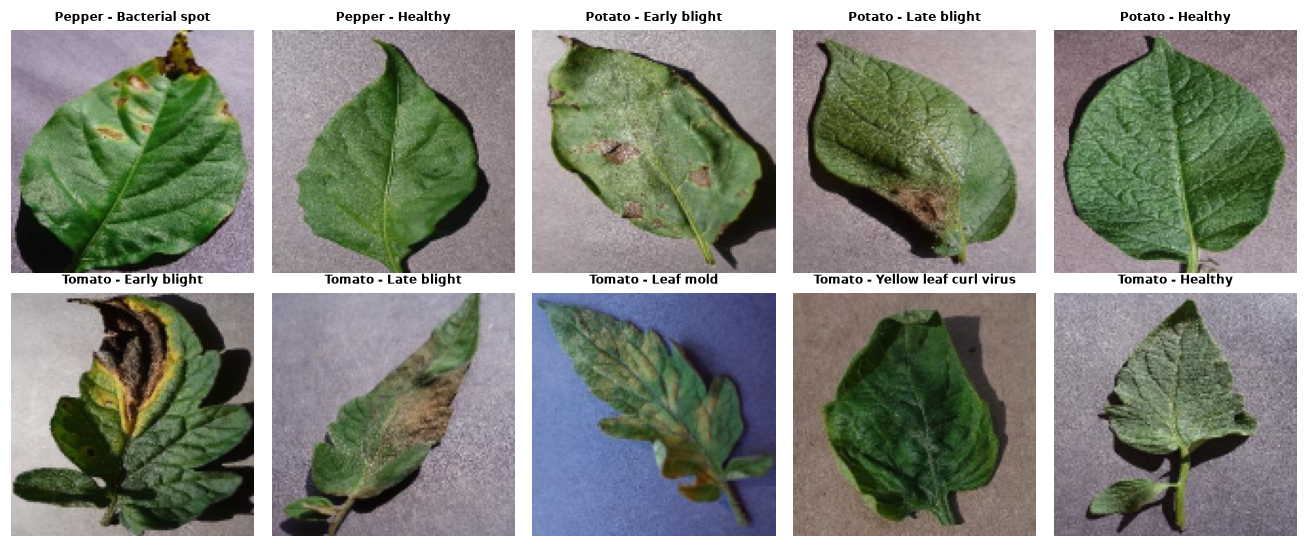

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(xtr[np.where(ytr == c)[0][0]]); ax.set_title(C.CLASS_NAMES[c], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### Augmentation (stateless, reproducible)

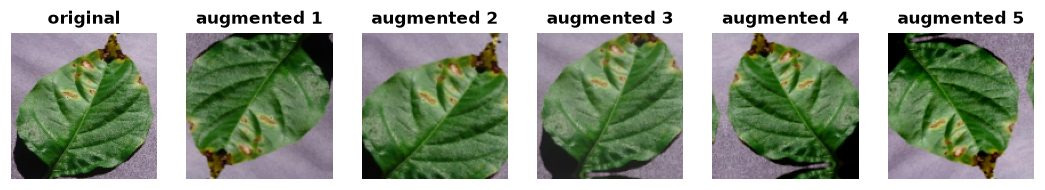

In [5]:
from src.common import augment
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(xtr[0]); axes[0].set_title("original")
for k, ax in enumerate(axes[1:]):
    a, _ = augment(tf.constant(k, tf.int64), tf.constant(xtr[:1]), tf.constant([0]))
    ax.imshow(a[0]); ax.set_title(f"augmented {k+1}")
for ax in axes: ax.axis("off")
plt.show()

## 2. Baseline CNN, underfitting and overfitting (Unit II)

In [6]:
from src.models import build_baseline
build_baseline().summary()
print("\nConvolution output size: floor((n + 2p - k) / s) + 1 =", (128 + 2*1 - 3)//1 + 1, "for conv1 (n=128, k=3, p=1, s=1)")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Dense)                 │ (None, 10)             │           970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,514 (435.60 KB)

 Trainable params: 111,034 (433.73 KB)

 Non-trainable params: 480 (1.88 KB)


Convolution output size: floor((n + 2p - k) / s) + 1 = 128 for conv1 (n=128, k=3, p=1, s=1)


,params,epochs_run,train_acc,val_acc,gap
underfit,162.0,20.0,0.130,0.152,-0.022
overfit,4216522.0,20.0,1.000,0.658,0.342
regularised,24490.0,30.0,0.725,0.682,0.043


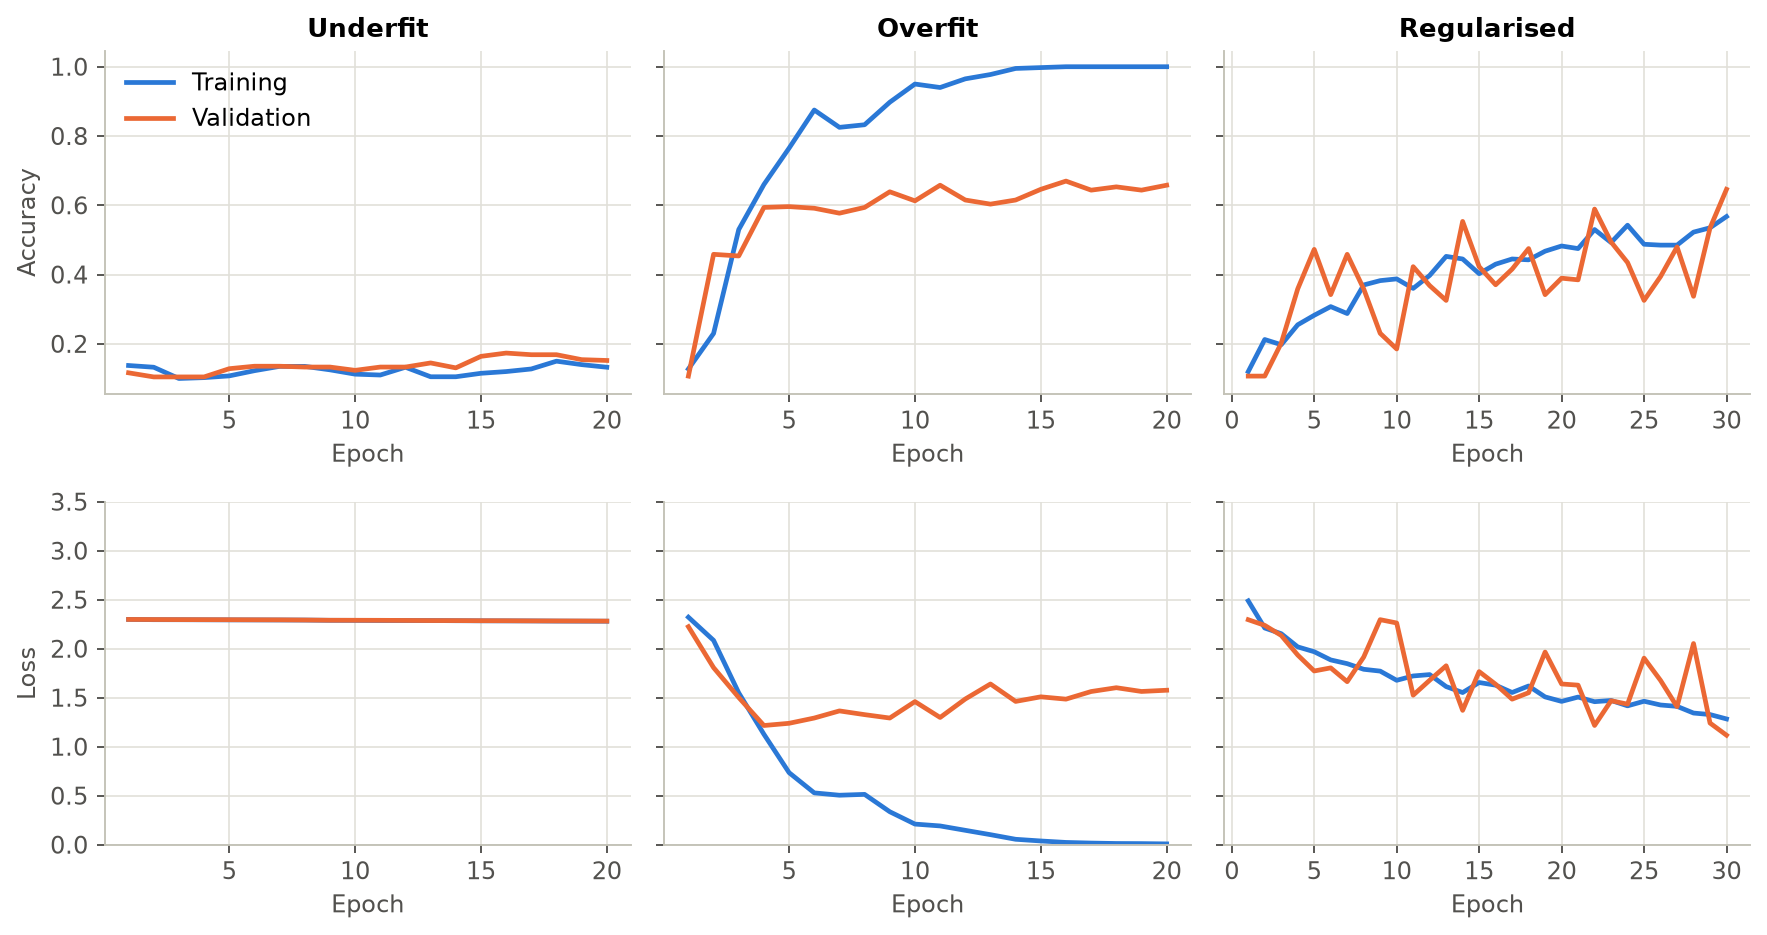

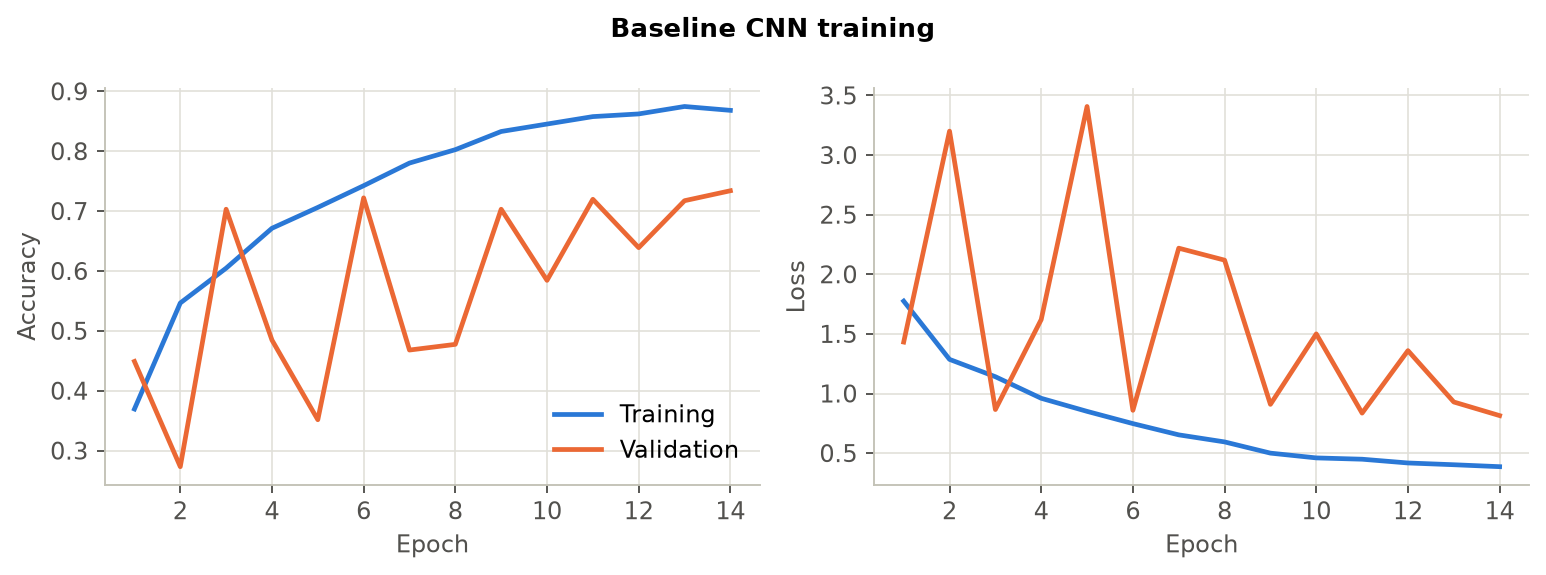

In [7]:
display(pd.DataFrame({k: {m: v[m] for m in ("params", "epochs_run", "train_acc", "val_acc", "gap")}
                      for k, v in metrics["fit_experiment"]["results"].items()}).T.round(3))
display(Image("assets/plots/overfit_underfit.png")); display(Image("assets/plots/baseline_curves.png"))

### A short live training run
Two epochs on 480 images, only to show the Keras compile / fit loop running inside the notebook. The reported models are trained by the scripts.

In [8]:
from src.common import seed_everything
seed_everything()
rng = np.random.default_rng(0); pick = rng.choice(len(xtr), 480, replace=False)
demo = build_baseline(img=64)
small = lambda x: np.stack([cv2.resize(i, (64, 64)) for i in x])
import cv2
demo.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
ds, steps = train_dataset(small(xtr[pick]), ytr[pick])
h = demo.fit(ds, steps_per_epoch=steps, epochs=2, validation_data=eval_dataset(small(xva), yva), verbose=2)

Epoch 1/2


15/15 - 14s - 959ms/step - accuracy: 0.2292 - loss: 2.3077 - val_accuracy: 0.1045 - val_loss: 2.4426


Epoch 2/2


15/15 - 6s - 391ms/step - accuracy: 0.3292 - loss: 1.8795 - val_accuracy: 0.2138 - val_loss: 2.3064


## 3. Hyperparameter tuning and optimizers (Units I and II)

,lr,dropout,batch,val_acc,val_loss,best_epoch,train_acc
0,0.0010,0.2,16,0.9216,0.2382,9,0.9786
1,0.0030,0.4,64,0.9192,0.2411,12,0.9557
2,0.0030,0.2,64,0.9074,0.2498,7,0.9662
3,0.0010,0.4,64,0.9074,0.2561,12,0.9259
4,0.0010,0.4,16,0.9097,0.2566,9,0.9413
5,0.0010,0.2,64,0.9050,0.2610,12,0.9562
6,0.0030,0.2,16,0.9240,0.2853,9,0.9707
7,0.0003,0.2,16,0.8979,0.2916,12,0.9383
8,0.0003,0.4,16,0.8979,0.3073,12,0.9030
9,0.0030,0.4,16,0.9097,0.3421,7,0.9319


,final_train_loss,final_val_acc,best_val_acc
SGD,0.2052,0.9002,0.9002
SGD + momentum,0.1458,0.9050,0.9121
RMSprop,0.0809,0.9192,0.9264
Adagrad,0.1701,0.9050,0.9097
Adam,0.1023,0.9074,0.9240


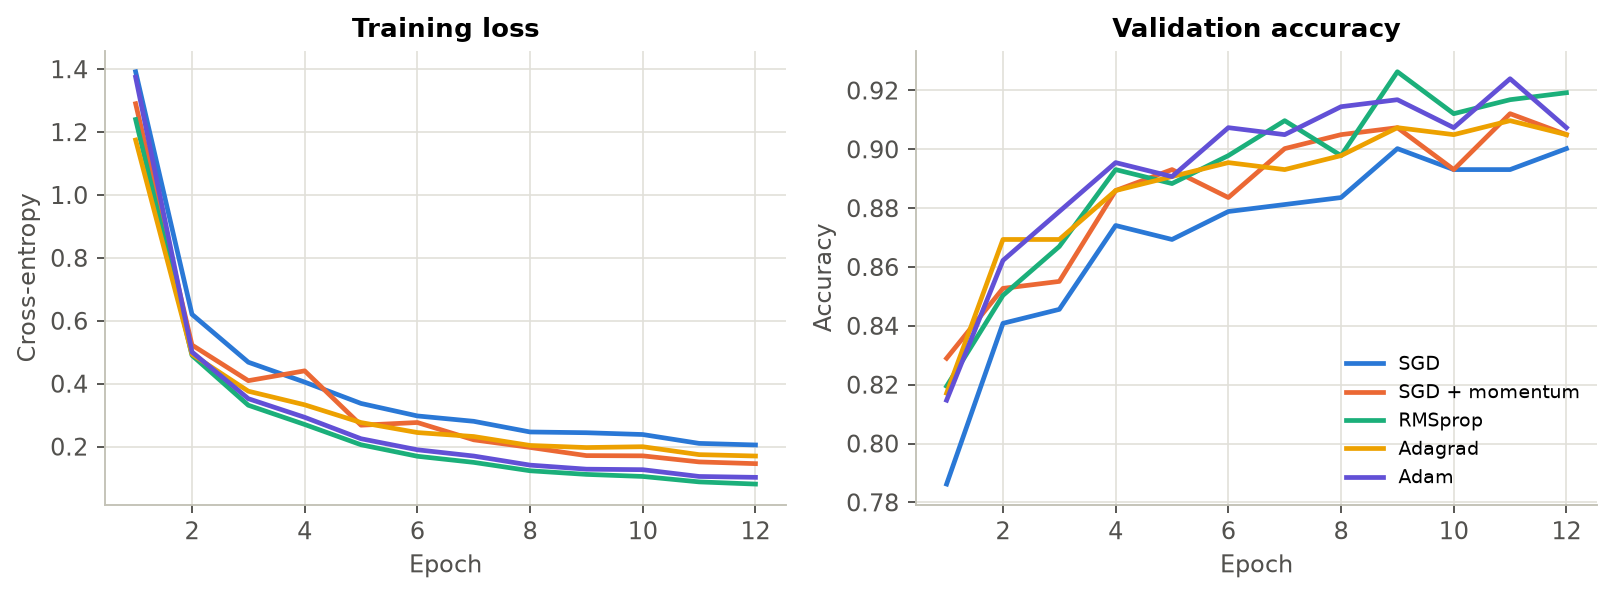

In [9]:
display(pd.DataFrame(metrics["tuning"]["table"]).round(4))
display(pd.DataFrame(metrics["tuning"]["optimizers"]).T.round(4))
display(Image("assets/plots/optimizer_comparison.png"))

## 4. Transfer learning with MobileNetV2 (Unit III)
A pretrained network first classifies a leaf with its original 1000 ImageNet classes, then we use our fine-tuned version.

backbone parameters: 2,257,984 | feature vector: (None, 1280)


{'params': 2270794, 'head_params': 12810, 'finetune_params': 1676170, 'val_acc_after_head': 0.8954869508743286, 'val_acc_after_ft': 0.940617561340332}


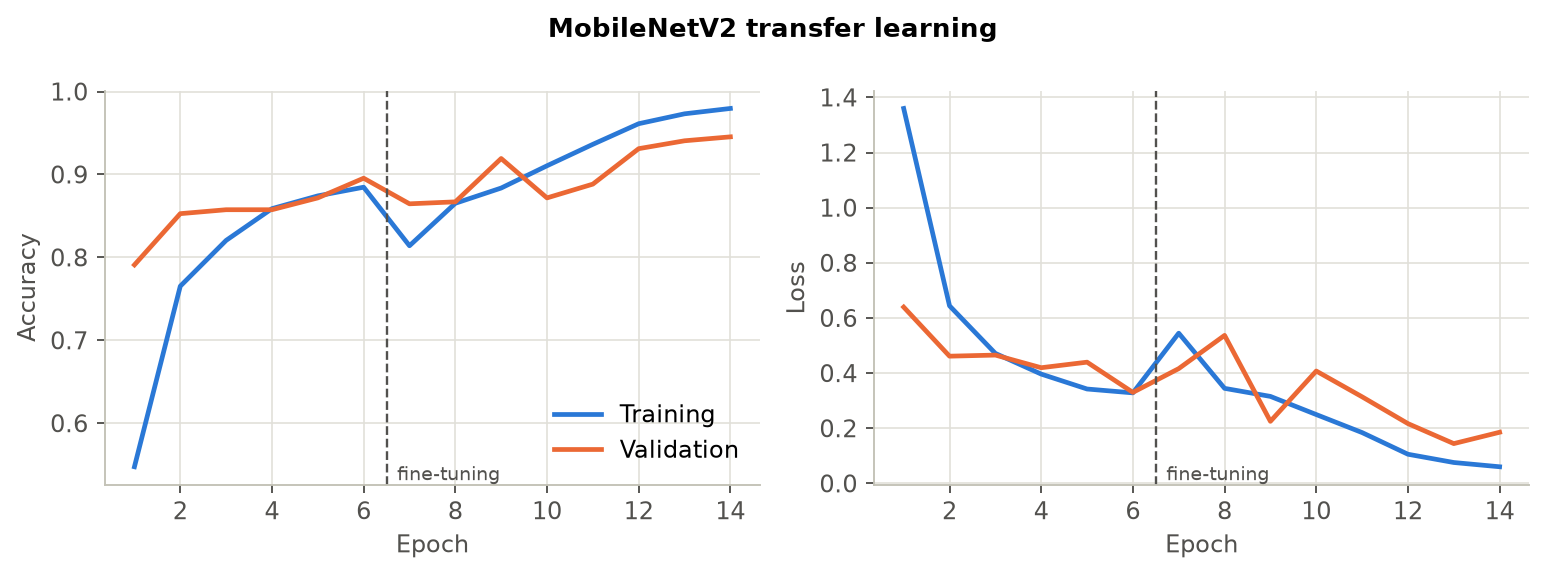

In [10]:
from src.models import build_transfer
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions
full = MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights="imagenet", pooling="avg")
print("backbone parameters:", f"{full.count_params():,}", "| feature vector:", full.output.shape)
tran = keras.models.load_model(C.MODELS / "transfer.keras"); base = keras.models.load_model(C.MODELS / "baseline.keras")
t = metrics["transfer"]
print({k: t[k] for k in ("params", "head_params", "finetune_params", "val_acc_after_head", "val_acc_after_ft")})
display(Image("assets/plots/transfer_curves.png"))

## 5. Test-set evaluation (recomputed live)

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
probs = {n: predict(m, xte) for n, m in (("baseline", base), ("transfer", tran))}
for n, p in probs.items():
    print(f"{n}: live accuracy {accuracy_score(yte, p.argmax(1)):.4f} | metrics.json {metrics['evaluation'][n]['accuracy']:.4f}")
print(classification_report(yte, probs["transfer"].argmax(1), target_names=C.CLASS_NAMES, digits=3))

baseline: live accuracy 0.9143 | metrics.json 0.9143
transfer: live accuracy 0.9476 | metrics.json 0.9476
                                 precision    recall  f1-score   support

        Pepper - Bacterial spot      1.000     0.932     0.965        44
               Pepper - Healthy      0.938     1.000     0.968        45
          Potato - Early blight      1.000     0.977     0.989        44
           Potato - Late blight      0.956     0.977     0.966        44
               Potato - Healthy      0.947     0.900     0.923        20
          Tomato - Early blight      0.886     0.886     0.886        44
           Tomato - Late blight      0.932     0.911     0.921        45
             Tomato - Leaf mold      0.909     0.909     0.909        44
Tomato - Yellow leaf curl virus      0.956     0.956     0.956        45
               Tomato - Healthy      0.957     1.000     0.978        45

                       accuracy                          0.948       420
                

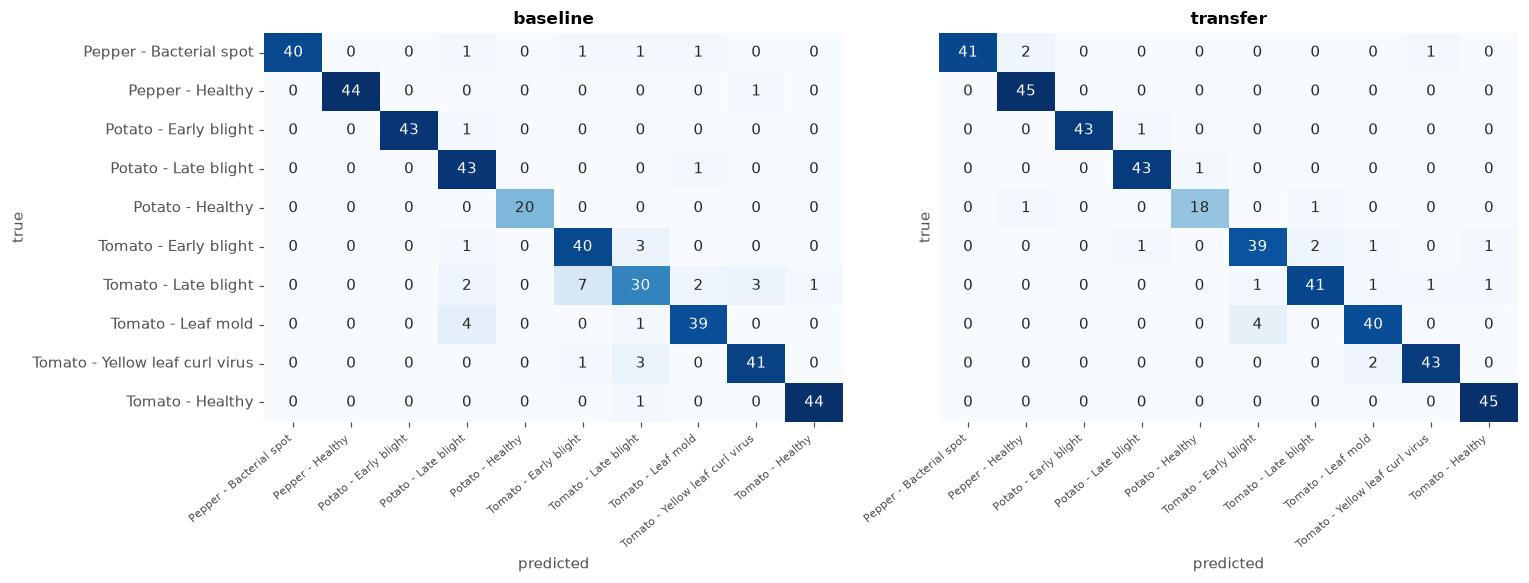

In [12]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, (n, p) in zip(axes, probs.items()):
    sns.heatmap(confusion_matrix(yte, p.argmax(1)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=C.CLASS_NAMES, yticklabels=C.CLASS_NAMES if ax is axes[0] else False)
    ax.set(title=n, xlabel="predicted", ylabel="true"); plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7)
plt.tight_layout(); plt.show()

## 6. Save, reload and compare predictions (Unit II)

In [13]:
import tempfile
p = Path(tempfile.mkdtemp()) / "copy.keras"
tran.save(p); again = keras.models.load_model(p)
diff = np.abs(predict(again, xte[:32]) - probs["transfer"][:32]).max()
print("largest difference after save -> load:", diff)

largest difference after save -> load: 0.0


## 7. Activation maps and Grad-CAM

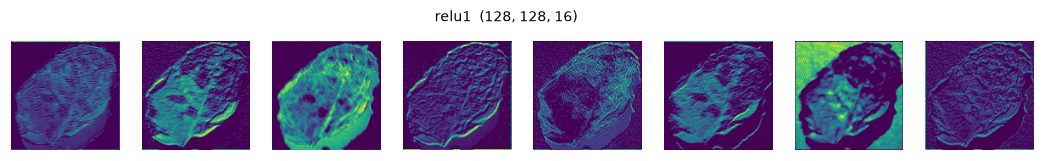

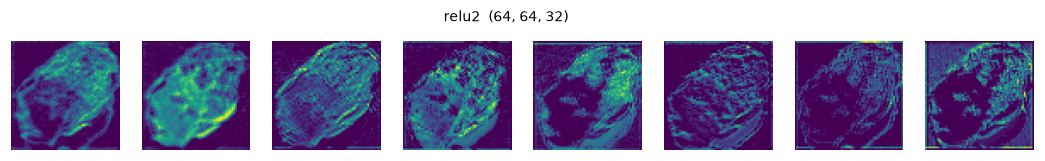

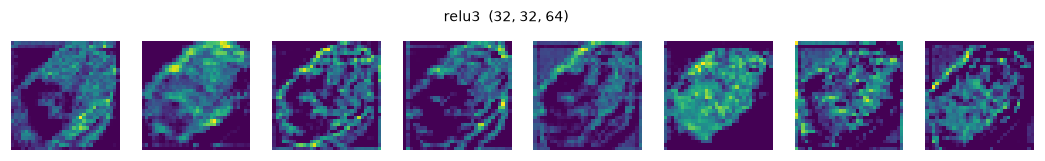

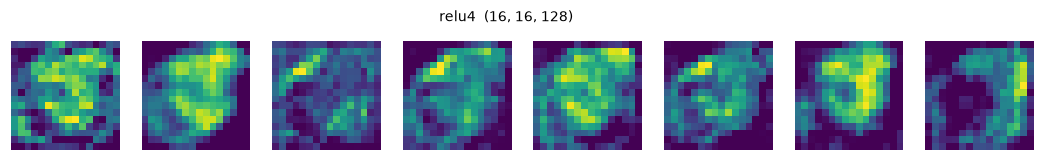

In [14]:
from src.gradcam import activation_maps, make_gradcam, overlay, LAST_CONV
img = to_float(xte[np.where(yte == 2)[0][0]])
for layer, m in activation_maps(base, img).items():
    fig, axes = plt.subplots(1, 8, figsize=(12, 1.6))
    for ax, ch in zip(axes, np.argsort(-m.mean((0, 1)))[:8]):
        ax.imshow(m[..., ch], cmap="viridis"); ax.axis("off")
    fig.suptitle(f"{layer}  {m.shape}", fontsize=9); plt.show()

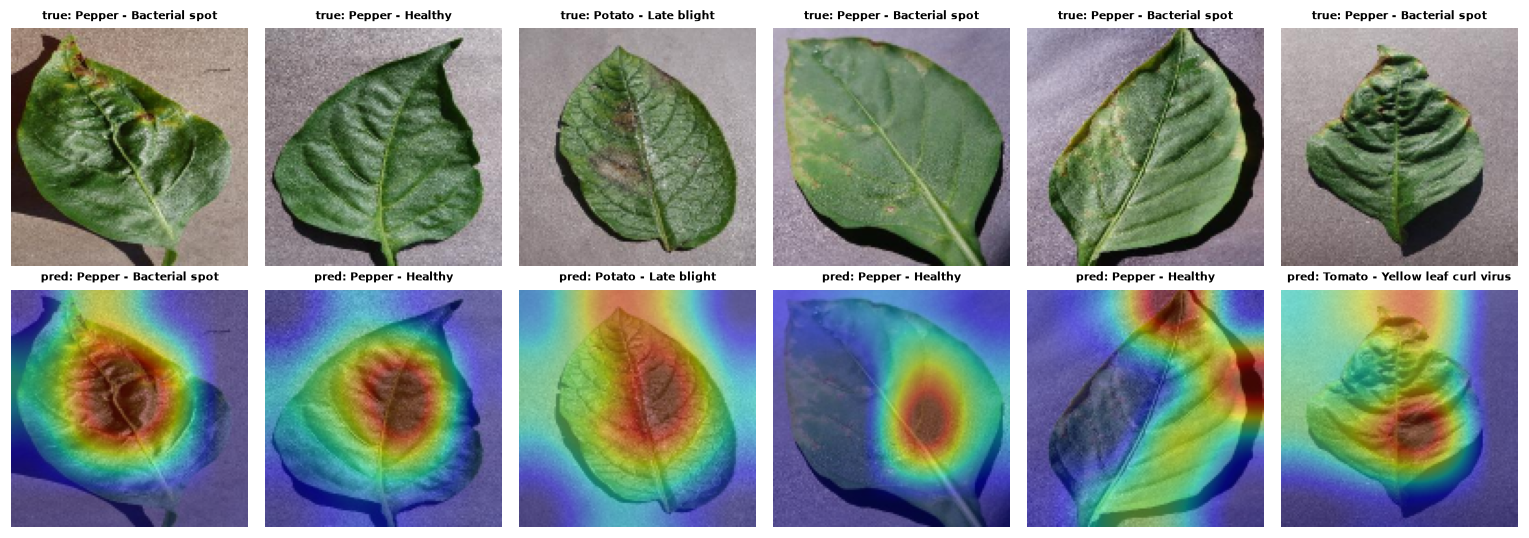

In [15]:
cam = make_gradcam(tran, LAST_CONV["transfer"])
yh = probs["transfer"].argmax(1)
idx = list(np.where(yh == yte)[0][[5, 60, 150]]) + list(np.where(yh != yte)[0][:3])
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(idx):
    im = to_float(xte[i]); axes[0, j].imshow(im); axes[1, j].imshow(overlay(im, cam(im)))
    axes[0, j].set_title(f"true: {C.CLASS_NAMES[yte[i]]}", fontsize=7); axes[1, j].set_title(f"pred: {C.CLASS_NAMES[yh[i]]}", fontsize=7)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Autoencoders (Unit IV)

compression 12288 B -> 1024 B {'mse': 0.0043331896886229515, 'psnr': 24.059079916262203, 'ssim': 0.6706870198249817}


noisy    {'mse': 0.009671948850154877, 'psnr': 20.150912311430837, 'ssim': 0.48454776406288147}


denoised {'mse': 0.001996136736124754, 'psnr': 27.127211907812544, 'ssim': 0.7690724730491638}


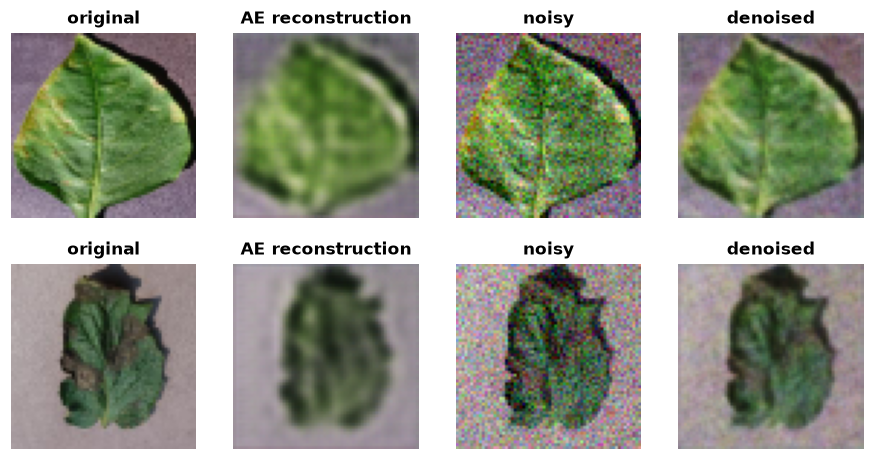

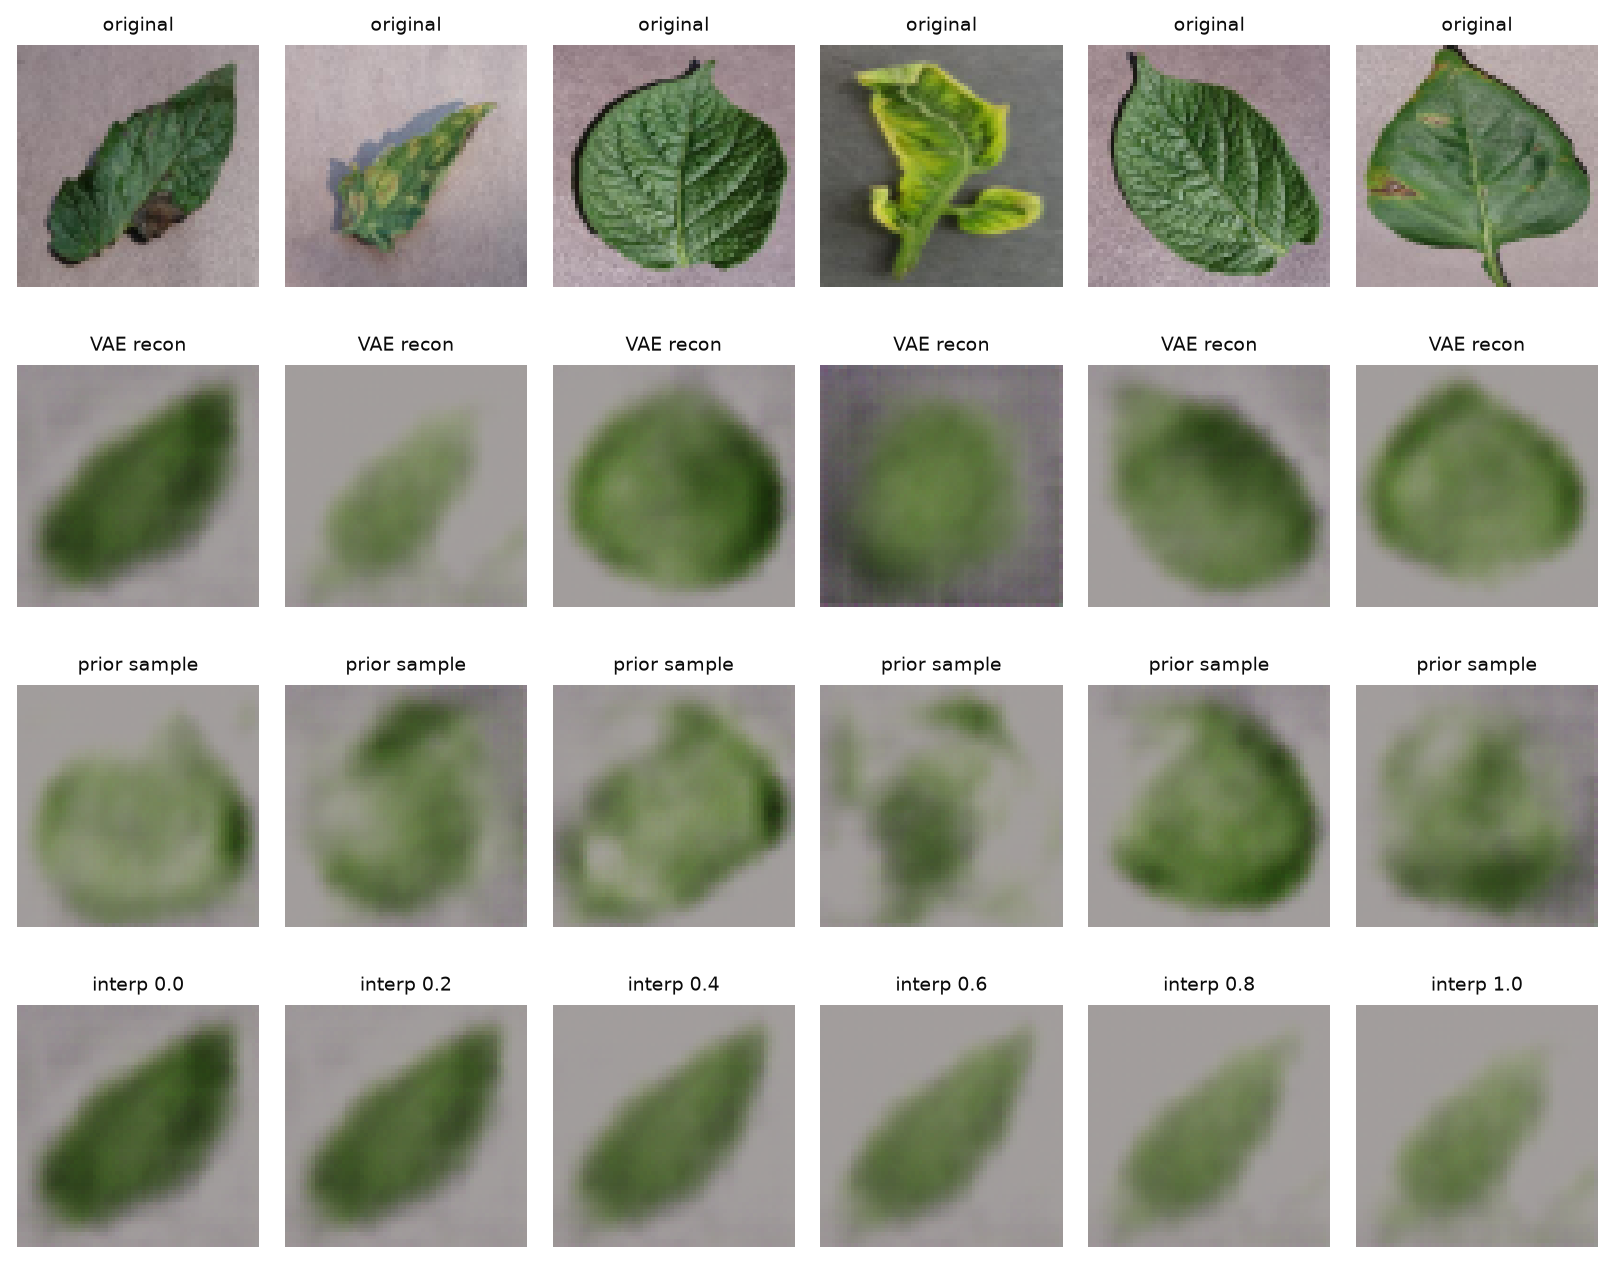

In [16]:
from src.models import encoder_decoder
from src.autoencoder import quality
ae = keras.models.load_model(C.MODELS / "autoencoder.keras"); dae = keras.models.load_model(C.MODELS / "denoiser.keras")
x64 = to_float(load_split("test", 64)[0])
enc, dec = encoder_decoder(ae)
code8 = np.round(enc.predict(x64, verbose=0) * 255).astype(np.uint8)
rec = dec.predict(code8.astype("float32") / 255, verbose=0)
noisy = np.clip(x64 + np.random.default_rng(4).normal(0, C.AE["noise"], x64.shape), 0, 1).astype("float32")
den = dae.predict(noisy, verbose=0)
print("compression", x64[0].size, "B ->", code8[0].size, "B", quality(x64, rec))
print("noisy   ", quality(x64, noisy)); print("denoised", quality(x64, den))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for r, i in enumerate((10, 250)):
    for ax, im, tt in zip(axes[r], (x64[i], rec[i], noisy[i], den[i]), ("original", "AE reconstruction", "noisy", "denoised")):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(tt); ax.axis("off")
plt.show()
display(Image("assets/plots/vae_grid.png"))

## 9. FGSM adversarial attack and defence (Unit VI)

,baseline,transfer,baseline_adv_trained
epsilon,,,
0.0000,0.914,0.948,0.867
0.0025,0.574,0.279,0.757
0.0050,0.374,0.105,0.657
0.0100,0.140,0.026,0.460
0.0200,0.040,0.024,0.279
0.0400,0.026,0.021,0.136
0.0800,0.081,0.071,0.098


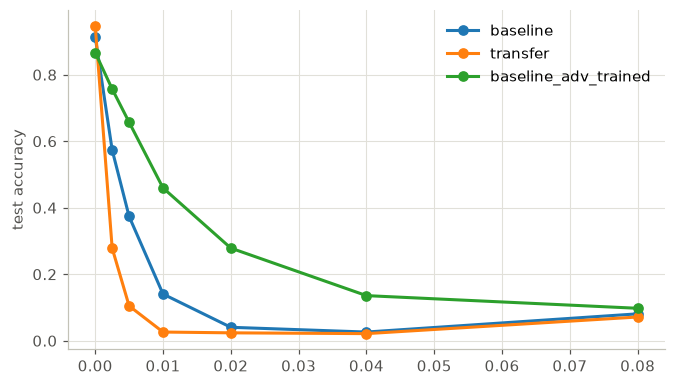

In [17]:
from src.fgsm import robustness
robust = keras.models.load_model(C.MODELS / "baseline_robust.keras")
live = {n: robustness(m, xte, yte) for n, m in (("baseline", base), ("transfer", tran), ("baseline_adv_trained", robust))}
display(pd.DataFrame(live, index=C.FGSM_EPS).round(3).rename_axis("epsilon"))
pd.DataFrame(live, index=C.FGSM_EPS).plot(marker="o", figsize=(7, 4), ylabel="test accuracy"); plt.show()

## 10. Background-bias probe
A random forest that sees only 8 border pixels. Anything above the majority rate means backgrounds leak labels.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from src.bias_probe import eight_pixels
rf = RandomForestClassifier(500, random_state=C.SEED, n_jobs=2, class_weight="balanced").fit(eight_pixels(xtr), ytr)
print("8-pixel accuracy", round(rf.score(eight_pixels(xte), yte), 4), "| stored", round(metrics["bias_probe"]["accuracy"], 4))

8-pixel accuracy 0.5214 | stored 0.5214


## 11. TensorBoard and the demo app
- `tensorboard --logdir logs`
- `streamlit run app/app.py`